<a href="https://colab.research.google.com/github/strangestmahi/statistical-foundation-of-data-science/blob/main/practical4ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Imported libraries needed for data analysis and visualization.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as pyplot

# Loaded the rating dataset and displayed its first few rows.

In [ ]:
ratings_url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-ST0151EN-SkillsNetwork/labs/teachingratings.csv"

ratings_df = pd.read_csv(ratings_url)

ratings_df.head()

,minority,age,gender,credits,beauty,eval,division,native,tenure,students,allstudents,prof,PrimaryLast,vismin,female,single_credit,upper_division,English_speaker,tenured_prof
0,yes,36,female,more,0.289916,4.3,upper,yes,yes,24,43,1,0,1,1,0,1,1,1
1,yes,36,female,more,0.289916,3.7,upper,yes,yes,86,125,1,0,1,1,0,1,1,1
2,yes,36,female,more,0.289916,3.6,upper,yes,yes,76,125,1,0,1,1,0,1,1,1
3,yes,36,female,more,0.289916,4.4,upper,yes,yes,77,123,1,1,1,1,0,1,1,1
4,no,59,male,more,-0.737732,4.5,upper,yes,yes,17,20,2,0,0,0,0,1,1,1


# Identified all repeated observations for the same instructor.

In [ ]:
duplicates = ratings_df[ratings_df.duplicated("prof", keep=False)]

duplicates

,minority,age,gender,credits,beauty,eval,division,native,tenure,students,allstudents,prof,PrimaryLast,vismin,female,single_credit,upper_division,English_speaker,tenured_prof
0,yes,36,female,more,0.289916,4.3,upper,yes,yes,24,43,1,0,1,1,0,1,1,1
1,yes,36,female,more,0.289916,3.7,upper,yes,yes,86,125,1,0,1,1,0,1,1,1
2,yes,36,female,more,0.289916,3.6,upper,yes,yes,76,125,1,0,1,1,0,1,1,1
3,yes,36,female,more,0.289916,4.4,upper,yes,yes,77,123,1,1,1,1,0,1,1,1
4,no,59,male,more,-0.737732,4.5,upper,yes,yes,17,20,2,0,0,0,0,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
451,no,32,male,more,1.231394,4.3,upper,yes,yes,52,86,93,1,0,0,0,1,1,1
452,yes,42,female,more,0.420400,3.3,upper,no,yes,48,84,94,0,1,1,0,1,0,1
453,yes,42,female,more,0.420400,3.3,upper,no,yes,52,67,94,0,1,1,0,1,0,1
454,yes,42,female,more,0.420400,3.2,upper,no,yes,54,66,94,0,1,1,0,1,0,1


# Calculated the average age and age variation for the complete dataset.

In [ ]:
print("Average age:", ratings_df["age"].mean())
print("Standard deviation:", ratings_df["age"].std())

Average age: 48.365010799136066
Standard deviation: 9.802742037864821


# Removed repeated instructor records and kept one observation per professor.

In [ ]:
one_professor = ratings_df.drop_duplicates("prof")

print("Number of observations:", len(one_professor))

Number of observations: 94


# Recalculated the age statistics using the 94 unique instructors.

In [ ]:
print("Average age:", one_professor["age"].mean())
print("Standard deviation:", one_professor["age"].std())


# Checked the categories available for course division.

In [ ]:
ratings_df["division"].unique()

array(['upper', 'lower'], dtype=object)

# Found the average evaluation score for each course division.

In [ ]:
division_eval = ratings_df.groupby("division")["eval"].mean()

print(division_eval)


division
lower    4.087261
upper    3.952614
Name: eval, dtype: float64


# Compared the average teaching evaluations using a bar chart.

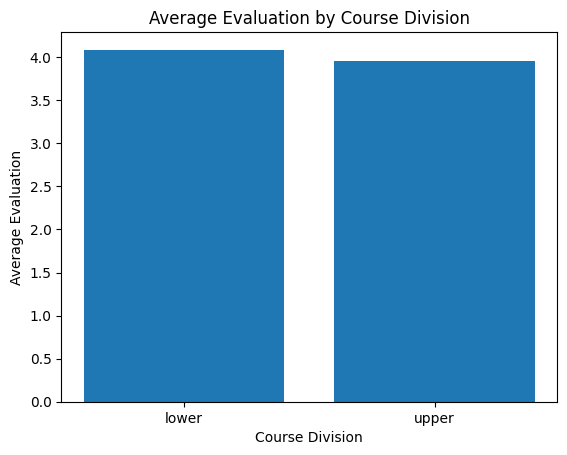

In [ ]:
pyplot.bar(division_eval.index, division_eval.values)

pyplot.xlabel("Course Division")
pyplot.ylabel("Average Evaluation")
pyplot.title("Average Evaluation by Course Division")

pyplot.show()


Yes, instructors teaching lower division courses recieves slightly higher average teaching evalutaion

# Used a scatterplot to examine the relationship between age and evaluation.

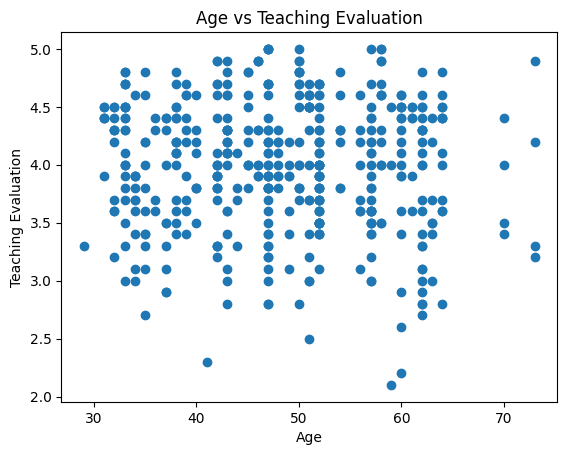

In [ ]:
pyplot.scatter(ratings_df["age"], ratings_df["eval"])

pyplot.xlabel("Age")
pyplot.ylabel("Teaching Evaluation")
pyplot.title("Age vs Teaching Evaluation")

pyplot.show()


The scatter plot indicates that there is no strong relationship between instructor age and teaching evaluation scores. Evaluation scores vary considerably across all age groups, suggesting that age alone is not a major factor determining teaching evaluations.

# Plotted male and female instructors separately to compare their patterns.

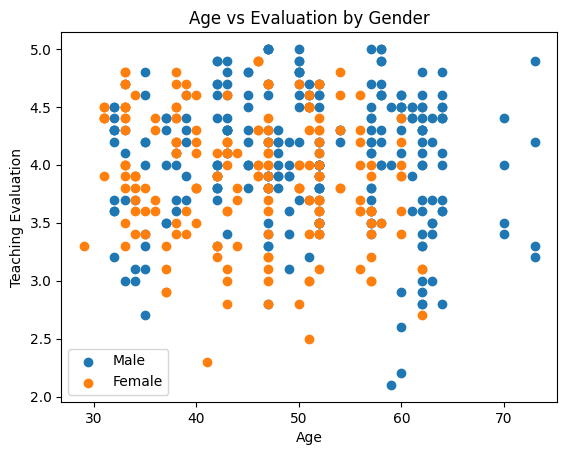

In [ ]:
male = ratings_df[ratings_df["gender"] == "male"]
female = ratings_df[ratings_df["gender"] == "female"]

pyplot.scatter(male["age"], male["eval"], label="Male")
pyplot.scatter(female["age"], female["eval"], label="Female")

pyplot.xlabel("Age")
pyplot.ylabel("Teaching Evaluation")
pyplot.title("Age vs Evaluation by Gender")
pyplot.legend()

pyplot.show()

he plot indicates that age does not have a strong relationship with teaching evaluation scores for either male or female instructors. Both genders show considerable variation in evaluation scores across different age groups.

# Compared age and evaluation across groups based on both gender and tenure.

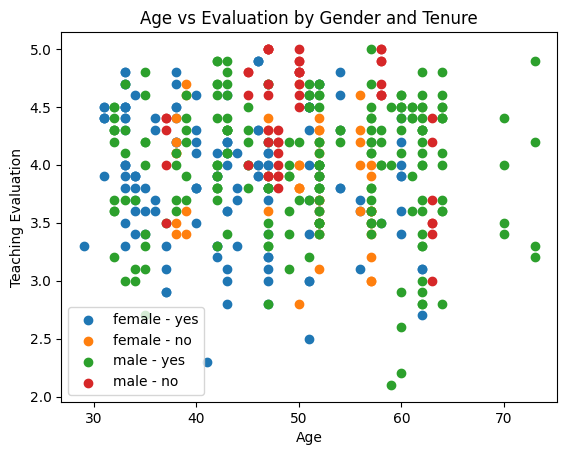

In [ ]:
for gender in ratings_df["gender"].unique():
    for tenure in ratings_df["tenure"].unique():
        data = ratings_df[
            (ratings_df["gender"] == gender) &
            (ratings_df["tenure"] == tenure)
        ]

        pyplot.scatter(
            data["age"],
            data["eval"],
            label=gender + " - " + tenure
        )

pyplot.xlabel("Age")
pyplot.ylabel("Teaching Evaluation")
pyplot.title("Age vs Evaluation by Gender and Tenure")
pyplot.legend()

pyplot.show()

The plot shows that teaching evaluation scores vary considerably across age groups for both genders and tenure statuses. There is no clear relationship between instructor age and evaluation scores, even after considering gender and tenure.